# 02 — Linear SVM and XGBoost; final comparison of four classifiers
COM747 · DS&ML CW2

Select **Python (DSML CW2)**. Run `01_logistic_random_forest.ipynb` first. This notebook trains two additional classifiers using the exact same discordance benchmark, partitions and feature definitions. It then freezes the model choices and thresholds and evaluates all four classifiers across A/B/C on the held-out test set. Do not use test results to tune or choose a new model.

## 1. Load shared configuration and helpers

In [1]:
from pathlib import Path
import hashlib, json, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix, precision_recall_curve,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

SEED = 42
JOBS = 2  # bounded parallelism; adjust for your machine
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if
    (p/'data/processed/feature_contract.json').is_file()), None)
if root is None:
    raise FileNotFoundError('Run cleaning/cleaning.ipynb and validation.ipynb first.')
DATA = root/'data/processed'
OUT = root/'models'/'outputs'
OUT.mkdir(parents=True, exist_ok=True)
contract = json.loads((DATA/'feature_contract.json').read_text())
report = json.loads((DATA/'validation_report.json').read_text())
if not report['passed']:
    raise ValueError('Data validation did not pass.')
def sha(path):
    with path.open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()
for name, expected in contract['output_sha256'].items():
    if sha(DATA/name) != expected:
        raise ValueError(f'{name} changed; rerun cleaning and validation.')
if sha(root/'data/raw/diabetic_data.csv') != contract['source_sha256']:
    raise ValueError('Raw data changed; rerun cleaning and validation.')
CONTRACT_HASH = sha(DATA/'feature_contract.json')
TARGET = contract['target']
GROUP = contract['group']
CLINICAL = contract['clinical_features']
CARE = contract['observed_care_features']
DISC = contract['planned_discordance_features']
SETS = {'A':contract['feature_set_A'], 'B':contract['feature_set_B'],
        'C':contract['feature_set_C_planned']}
CATS = contract['clinical_categorical']
FORBIDDEN = {TARGET, GROUP, contract['id'], 'split', 'readmitted', *contract['audit_only']}
assert all(not FORBIDDEN.intersection(cols) for cols in SETS.values())

def load(name):
    d = pd.read_csv(DATA/f'{name}.csv', keep_default_na=False, na_values=['?', ''],
                   dtype={GROUP:str, contract['id']:str})
    for col in CATS:
        # Keep coded categories categorical, including admission ID codes.
        if col in ['admission_type_id', 'admission_source_id']:
            d[col] = pd.to_numeric(d[col], errors='raise').map(lambda x: str(int(x)) if pd.notna(x) else np.nan).astype(object)
        else:
            d[col] = d[col].map(lambda x: str(x) if pd.notna(x) else np.nan).astype(object)
    for col in contract['clinical_numeric'] + CARE:
        d[col] = pd.to_numeric(d[col], errors='raise').astype(float)
    assert set(d[TARGET]) == {0,1} and d[GROUP].notna().all()
    return d

def preprocess(cols):
    cat = [c for c in cols if c in CATS]
    num = [c for c in cols if c not in CATS]
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                              ('scale', StandardScaler())]), num),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)
    ])

def score(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    return model.decision_function(X)  # SVM margins, not probabilities

def threshold_for_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros_like(t), where=(p[:-1]+r[:-1])>0)
    return float(t[np.argmax(f)])

def metrics(y, s, threshold):
    pred = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return dict(AP=average_precision_score(y,s), ROC_AUC=roc_auc_score(y,s),
                precision=precision_score(y,pred,zero_division=0), recall=recall_score(y,pred,zero_division=0),
                F1=f1_score(y,pred,zero_division=0), FNR=fn/(fn+tp),
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp), threshold=threshold)

def fit_family(name, candidates, train, val):
    rows, winners, trials = [], {}, []
    for label, cols in SETS.items():
        best = None
        for config, estimator in candidates():
            pipe = Pipeline([('preprocess', preprocess(cols)), ('model', estimator)])
            start = time.perf_counter()
            pipe.fit(train[cols], train[TARGET])
            elapsed = time.perf_counter()-start
            s = score(pipe, val[cols])
            ap = average_precision_score(val[TARGET], s)
            trials.append(dict(model=name, feature_set=label, config=config, AP=ap, fit_seconds=elapsed))
            if best is None or ap > best['AP']:
                best = dict(AP=ap, config=config, pipeline=pipe, scores=s, fit_seconds=elapsed)
        t = threshold_for_f1(val[TARGET], best['scores'])
        rows.append(dict(model=name, feature_set=label, config=best['config'], fit_seconds=best['fit_seconds'],
                         **metrics(val[TARGET], best['scores'], t)))
        winners[(name,label)] = dict(pipeline=best['pipeline'], threshold=t, config=best['config'])
    return rows, winners, trials

print('Project:', root, '| Kernel:', sys.executable)
print('Data validation passed; held-out test is reserved until final evaluation.')

Project: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /Data-science-and-Machine-Learning-Course-work | Kernel: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /.venv/bin/python
Data validation passed; held-out test is reserved until final evaluation.


## 2. Restore the first notebook’s locally generated artefacts

In [2]:
from xgboost import XGBClassifier
bundle = joblib.load(OUT/'discordance_bundle.joblib')
part1 = joblib.load(OUT/'classifiers_part1.joblib')
assert bundle['contract_hash'] == part1['contract_hash'] == CONTRACT_HASH
assert part1['discordance_hash'] == sha(OUT/'discordance_bundle.joblib')
train, val = bundle['train'], bundle['validation']
assert set(train[GROUP]).isdisjoint(val[GROUP])
print('Shared benchmark and classifiers restored.')

Shared benchmark and classifiers restored.


## 3. Classifier 3 — Linear Support Vector Machine
Linear SVM is chosen for scalability on the full dataset. Decision margins support AP, ROC-AUC and threshold selection but are not probabilities. No probability calibration is claimed.

In [3]:
def svm_candidates():
    for c in [0.01, 0.1, 1.0]:
        yield f'C={c}', LinearSVC(C=c, class_weight='balanced', dual=False, max_iter=3000, random_state=SEED)
svm_rows, svm_models, svm_trials = fit_family('Linear SVM', svm_candidates, train, val)
display(pd.DataFrame(svm_rows).round(4))

,model,feature_set,config,fit_seconds,AP,ROC_AUC,precision,recall,F1,FNR,TN,FP,FN,TP,threshold
0,Linear SVM,A,C=0.01,0.2870,0.2006,0.6396,0.1901,0.4245,0.2626,0.5755,13514,4093,1303,961,0.0499
1,Linear SVM,B,C=0.01,0.2613,0.2014,0.6444,0.1730,0.5415,0.2622,0.4585,11747,5860,1038,1226,-0.0006
2,Linear SVM,C,C=0.01,0.3656,0.2010,0.6448,0.1802,0.4947,0.2642,0.5053,12511,5096,1144,1120,0.0242


## 4. Classifier 4 — XGBoost
Class weighting is computed exclusively on training outcomes. Histogram trees and bounded CPU parallelism keep runtime manageable.

In [4]:
ratio = (train[TARGET]==0).sum()/(train[TARGET]==1).sum()
def xgb_candidates():
    for depth in [3,5,7]:
        yield f'max_depth={depth}', XGBClassifier(n_estimators=150, max_depth=depth,
            learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=float(ratio), tree_method='hist', eval_metric='logloss',
            random_state=SEED, n_jobs=JOBS)
xgb_rows, xgb_models, xgb_trials = fit_family('XGBoost', xgb_candidates, train, val)
display(pd.DataFrame(xgb_rows).round(4))

,model,feature_set,config,fit_seconds,AP,ROC_AUC,precision,recall,F1,FNR,TN,FP,FN,TP,threshold
0,XGBoost,A,max_depth=3,0.6280,0.2110,0.6444,0.1994,0.4024,0.2667,0.5976,13950,3657,1353,911,0.5438
1,XGBoost,B,max_depth=5,0.6594,0.2118,0.6468,0.1874,0.4651,0.2672,0.5349,13041,4566,1211,1053,0.5228
2,XGBoost,C,max_depth=3,0.6346,0.2132,0.6491,0.1943,0.4329,0.2682,0.5671,13543,4064,1284,980,0.5362


## 5. Lock all 12 configurations before reading test outcomes
The primary B-versus-C comparison uses the family with the highest validation AP for conventional Set B. This fixes one family without selecting it for its apparent discordance gain. Report every family as secondary comparisons. The best overall validation configuration is selected separately for the illustrative confusion matrix.

In [5]:
part2_results = pd.DataFrame(svm_rows + xgb_rows)
part2_results.to_csv(OUT/'validation_part2.csv',index=False)
pd.DataFrame(svm_trials + xgb_trials).to_csv(OUT/'tuning_part2.csv',index=False)
all_models = {**part1['models'], **svm_models, **xgb_models}
# Recompute validation results from the actual saved winners to avoid stale CSVs.
locked_rows = []
for (name,label), entry in all_models.items():
    s = score(entry['pipeline'], val[SETS[label]])
    locked_rows.append(dict(model=name, feature_set=label, config=entry['config'],
        **metrics(val[TARGET],s,entry['threshold'])))
validation = pd.DataFrame(locked_rows)
primary_family = validation.query("feature_set == 'B'").sort_values('AP',ascending=False).iloc[0]['model']
champ = validation.sort_values('AP',ascending=False).iloc[0]
champ_key = (champ['model'],champ['feature_set'])
assert len(all_models)==12
validation.to_csv(OUT/'validation_all.csv',index=False)
joblib.dump(dict(contract_hash=CONTRACT_HASH, models=all_models, primary_family=primary_family,
                 champion=champ_key), OUT/'locked_classifiers.joblib',compress=3)
(OUT/'evaluation_lock.json').write_text(json.dumps(dict(contract_hash=CONTRACT_HASH,
    model_hash=sha(OUT/'locked_classifiers.joblib'), discordance_hash=sha(OUT/'discordance_bundle.joblib'),
    primary_family=primary_family, champion=list(champ_key)),indent=2))
display(validation[['model','feature_set','AP','recall','F1','FNR']].round(4))
print('Locked primary family:',primary_family, '| Validation champion:',champ_key)

,model,feature_set,AP,recall,F1,FNR
0,Logistic Regression,A,0.2022,0.4240,0.2637,0.5760
1,Logistic Regression,B,0.2030,0.3737,0.2630,0.6263
2,Logistic Regression,C,0.2027,0.5066,0.2648,0.4934
3,Random Forest,A,0.2064,0.3936,0.2657,0.6064
4,Random Forest,B,0.2089,0.4757,0.2686,0.5243
5,Random Forest,C,0.2052,0.4139,0.2631,0.5861
6,Linear SVM,A,0.2006,0.4245,0.2626,0.5755
7,Linear SVM,B,0.2014,0.5415,0.2622,0.4585
8,Linear SVM,C,0.2010,0.4947,0.2642,0.5053
9,XGBoost,A,0.2110,0.4024,0.2667,0.5976


Locked primary family: XGBoost | Validation champion: ('XGBoost', 'C')


## 6. Final held-out test evaluation
Run once the group has agreed on the methodology. No refitting, threshold optimisation or feature selection on test. The test set is not an external or temporal validation cohort.

In [6]:
test = load('test')
assert set(test[GROUP]).isdisjoint(set(train[GROUP]) | set(val[GROUP]))
expected = bundle['benchmark'].predict(test[CLINICAL])
test[DISC] = (test[CARE].to_numpy() - expected)/bundle['scale']
assert np.isfinite(test[DISC].to_numpy()).all()
test_reg = pd.DataFrame([dict(dimension=c, partition='test', MAE=mean_absolute_error(test[c],expected[:,j]),
    RMSE=np.sqrt(mean_squared_error(test[c],expected[:,j]))) for j,c in enumerate(CARE)])
test_reg.to_csv(OUT/'expected_care_test_metrics.csv',index=False)
scores, rows = {}, []
for (name,label), entry in all_models.items():
    s = score(entry['pipeline'], test[SETS[label]])
    scores[(name,label)] = s
    rows.append(dict(model=name, feature_set=label, config=entry['config'],
        **metrics(test[TARGET], s, entry['threshold'])))
results = pd.DataFrame(rows)
results.to_csv(OUT/'test_metrics_all.csv',index=False)
display(results.round(4))
print('Test no-skill AP baseline:',test[TARGET].mean())

,model,feature_set,config,AP,ROC_AUC,precision,recall,F1,FNR,TN,FP,FN,TP,threshold
0,Logistic Regression,A,C=0.1,0.1857,0.6360,0.1854,0.4147,0.2563,0.5853,13486,4120,1324,938,0.5280
1,Logistic Regression,B,C=0.1,0.1858,0.6386,0.1886,0.3523,0.2457,0.6477,14178,3428,1465,797,0.5503
2,Logistic Regression,C,C=0.1,0.1860,0.6396,0.1732,0.4929,0.2563,0.5071,12283,5323,1147,1115,0.5095
3,Random Forest,A,max_depth=16,0.1842,0.6335,0.1916,0.3806,0.2549,0.6194,13973,3633,1401,861,0.5206
4,Random Forest,B,max_depth=8,0.1858,0.6370,0.1783,0.4576,0.2566,0.5424,12836,4770,1227,1035,0.5117
5,Random Forest,C,max_depth=None,0.1863,0.6399,0.1854,0.4005,0.2535,0.5995,13625,3981,1356,906,0.4270
6,Linear SVM,A,C=0.01,0.1841,0.6338,0.1845,0.4134,0.2551,0.5866,13473,4133,1327,935,0.0499
7,Linear SVM,B,C=0.01,0.1844,0.6363,0.1668,0.5243,0.2531,0.4757,11681,5925,1076,1186,-0.0006
8,Linear SVM,C,C=0.01,0.1844,0.6376,0.1746,0.4814,0.2562,0.5186,12457,5149,1173,1089,0.0242
9,XGBoost,A,max_depth=3,0.1897,0.6413,0.1917,0.3846,0.2559,0.6154,13938,3668,1392,870,0.5438


Test no-skill AP baseline: 0.11385141936782767


## 7. Compare feature sets and inspect false negatives

feature_set,A,B,C,C_minus_B
model,,,,
Linear SVM,0.1841,0.1844,0.1844,0.0000
Logistic Regression,0.1857,0.1858,0.1860,0.0002
Random Forest,0.1842,0.1858,0.1863,0.0005
XGBoost,0.1897,0.1863,0.1910,0.0047


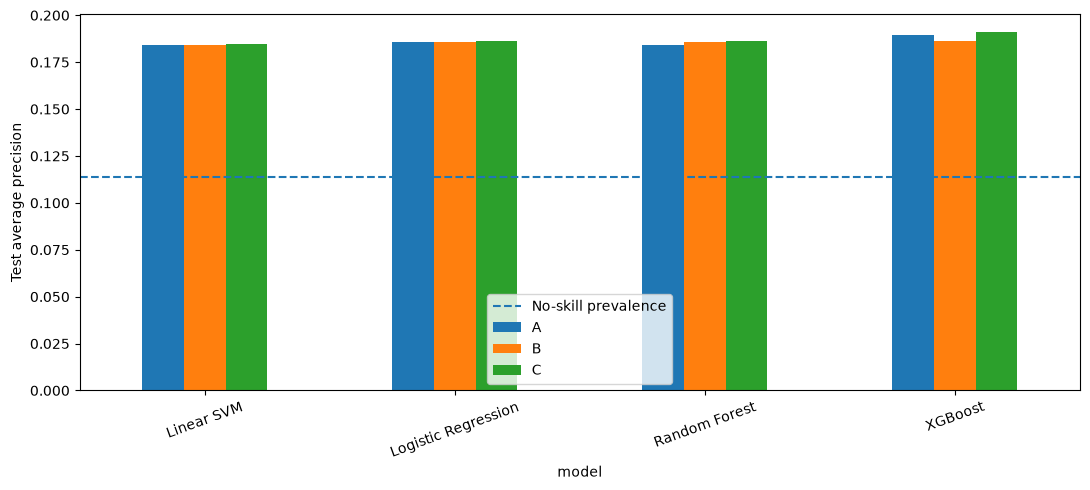

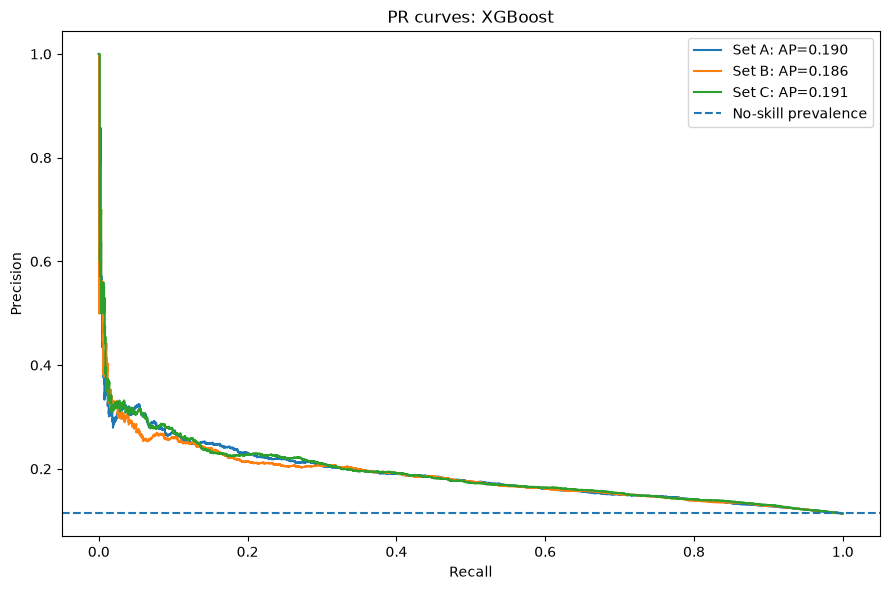

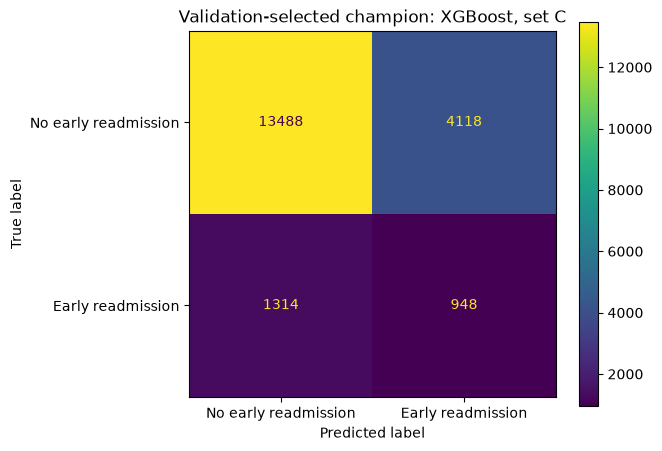

In [7]:
ap = results.pivot(index='model', columns='feature_set', values='AP')[['A','B','C']]
ap['C_minus_B'] = ap['C'] - ap['B']
display(ap.round(4))
ap.to_csv(OUT/'test_ap_comparison.csv')
ap[['A','B','C']].plot.bar(figsize=(11,5))
plt.axhline(test[TARGET].mean(),linestyle='--',label='No-skill prevalence')
plt.ylabel('Test average precision'); plt.xticks(rotation=20); plt.legend(); plt.tight_layout(); plt.show()
plt.figure(figsize=(9,6))
for label in SETS:
    p,r,_ = precision_recall_curve(test[TARGET], scores[(primary_family,label)])
    plt.plot(r,p,label=f'Set {label}: AP={ap.loc[primary_family,label]:.3f}')
plt.axhline(test[TARGET].mean(),linestyle='--',label='No-skill prevalence')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'PR curves: {primary_family}'); plt.legend(); plt.tight_layout(); plt.show()
entry = all_models[champ_key]
ConfusionMatrixDisplay.from_predictions(test[TARGET],(scores[champ_key]>=entry['threshold']).astype(int),
    labels=[0,1],display_labels=['No early readmission','Early readmission'])
plt.title(f'Validation-selected champion: {champ_key[0]}, set {champ_key[1]}'); plt.tight_layout(); plt.show()

## 8. Primary paired patient-bootstrap comparison (RQ2)
Resample patients with replacement, retaining all their encounters and comparing Sets B and C on the same resamples. This estimates test sampling uncertainty for fixed fitted models, not retraining variability. A positive AP difference favours C; an interval crossing zero is inconclusive. This is an exploratory internal validation, not clinical proof.

In [8]:
y = test[TARGET].to_numpy()
b, c = scores[(primary_family,'B')], scores[(primary_family,'C')]
patient_codes, unique_patients = pd.factorize(test[GROUP])
rng = np.random.default_rng(SEED)
deltas = []
N_BOOT = 300
for _ in range(N_BOOT):
    counts = np.bincount(rng.integers(0,len(unique_patients),size=len(unique_patients)), minlength=len(unique_patients))
    w = counts[patient_codes]
    if w[y==0].sum()==0 or w[y==1].sum()==0:
        continue
    deltas.append(average_precision_score(y,c,sample_weight=w)-average_precision_score(y,b,sample_weight=w))
assert len(deltas)>0
lo,hi = np.quantile(deltas,[0.025,0.975])
primary = pd.DataFrame([dict(model=primary_family, AP_B=average_precision_score(y,b),
    AP_C=average_precision_score(y,c), delta_AP=average_precision_score(y,c)-average_precision_score(y,b),
    CI_low=lo, CI_high=hi, bootstrap_replicates=len(deltas))])
display(primary.round(4)); primary.to_csv(OUT/'primary_paired_bootstrap.csv',index=False)

,model,AP_B,AP_C,delta_AP,CI_low,CI_high,bootstrap_replicates
0,XGBoost,0.1863,0.191,0.0047,-0.0002,0.0101,300


## 9. Supporting demographic error audit
Compare false-negative rates for the primary family's B and C models using their locked thresholds. Suppress groups with fewer than 20 distinct patients or fewer than 20 positive/negative encounters. This descriptive audit is not a complete fairness assessment; different group error rates can reflect sample size, data quality, historical practices or unmeasured clinical complexity.

In [9]:
audit = []
for label in ['B','C']:
    key = (primary_family,label)
    pred = (scores[key]>=all_models[key]['threshold']).astype(int)
    for col in ['age','gender','race']:
        for group, d in test.assign(pred=pred, demographic=test[col].fillna('Missing')).groupby('demographic'):
            positives = int(d[TARGET].sum()); negatives = len(d)-positives
            if min(d[GROUP].nunique(),positives,negatives)<20:
                audit.append(dict(feature_set=label, attribute=col, group=group,status='Suppressed'))
                continue
            tn,fp,fn,tp = confusion_matrix(d[TARGET],d['pred'],labels=[0,1]).ravel()
            audit.append(dict(feature_set=label,attribute=col,group=group,status='Reported',
                encounters=len(d),recall=tp/(tp+fn),FNR=fn/(tp+fn),FPR=fp/(fp+tn)))
audit = pd.DataFrame(audit)
display(audit.round(4)); audit.to_csv(OUT/'demographic_error_audit.csv',index=False)

,feature_set,attribute,group,status,encounters,recall,FNR,FPR
0,B,age,[0-10),Suppressed,NaN,NaN,NaN,NaN
1,B,age,[10-20),Suppressed,NaN,NaN,NaN,NaN
2,B,age,[20-30),Reported,318.0,0.5814,0.4186,0.2436
3,B,age,[30-40),Reported,706.0,0.5287,0.4713,0.2294
4,B,age,[40-50),Reported,2004.0,0.4817,0.5183,0.2038
5,B,age,[50-60),Reported,3384.0,0.3505,0.6495,0.1757
6,B,age,[60-70),Reported,4329.0,0.4890,0.5110,0.2627
7,B,age,[70-80),Reported,5204.0,0.4511,0.5489,0.2991
8,B,age,[80-90),Reported,3250.0,0.4935,0.5065,0.3566
9,B,age,[90-100),Reported,503.0,0.3929,0.6071,0.2461


## 10. Interpretation and remaining work
- RQ2: use primary paired AP difference and uncertainty, plus recall, F1, false-negative rate and all-model comparisons. A null or negative improvement is a valid result.
- RQ1 still requires adjusted association analysis, accounting for repeated patients, and optional clustering as supporting work. Do not interpret predictive performance as causality.
- Model artefacts are trusted local joblib files only. Do not load unknown joblib files or publish patient-level artefacts. Report computational runtime and actual model settings. The historical dataset cannot establish actual cost, treatment appropriateness or benefits from intervention.